### In this notebook i will look at the time-step $dt$ in the pde solver.

From experience the KdV solver requires finer time-steps than Whitham, why this is the case i dont know, but i can document it

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from camera.help import *

from waves.waveGenCamera import *
from waves.soliton import kdv_cnoidal, soliton

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

To limit errors from other methods we can create a cnoidal wave, and solve it forward. 

In [2]:
t_steps = np.geomspace(1e-3, 1e-5, 5)
N = 2**7
P = 8*np.pi # close to sech^2 wave

amp = 1

T = 0.5

In [3]:
cameras, ts, etas, cns = [], [], [], []
for dt in t_steps:
    nt = int(round(T/dt))
    t = dt*np.arange(nt + 1)               # same grid the solver saves on: t=0 ... t=T
    c = Camera(P, N, dt)
    cn, cm, m = kdv_cnoidal(P, amp, 0, c.x, t)
    tw = KdV(camera=c, T=T, u0=cn[0])
    t_sol, eta = tw.ifrk4()               
    assert eta.shape == cn.shape, (eta.shape, cn.shape)
    cameras.append(c); ts.append(t_sol); etas.append(eta); cns.append(cn)

KeyboardInterrupt: 

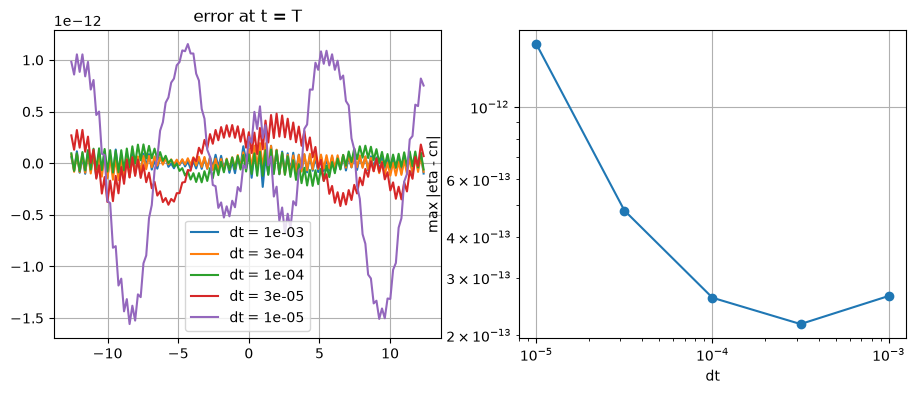

In [ ]:
diff = [eta - cn for eta, cn in zip(etas, cns)]
err  = [np.max(np.abs(d)) for d in diff]          # max over all t and x

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, d, dt in zip(cameras, diff, t_steps):
    ax[0].plot(c.x, d[-1], label=f"dt = {dt:.0e}")
ax[0].set_title("error at t = T"); ax[0].legend(); ax[0].grid(True)

ax[1].loglog(t_steps, err, 'o-')
ax[1].set_xlabel("dt"); ax[1].set_ylabel("max |eta - cn|"); ax[1].grid(True)
plt.show()

It can look like there is a minimum for $dt \in [10^{-3}, 10^{-4}]$

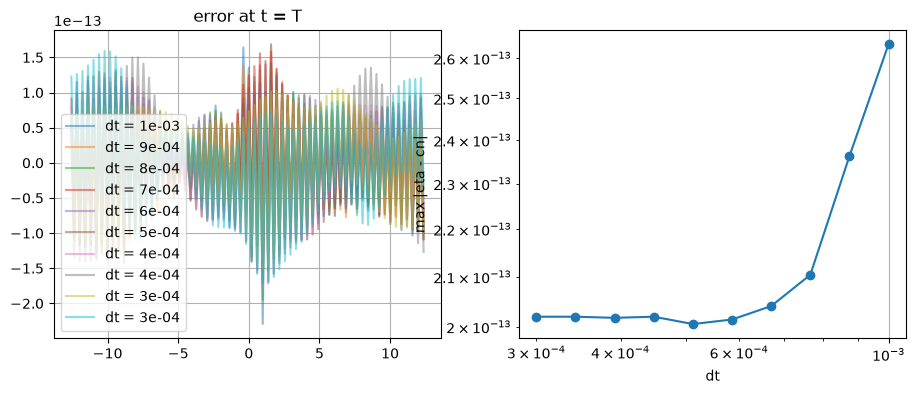

5


In [ ]:
t_steps = np.geomspace(1e-3, 3e-4, 10)
N = 2**7
P = 8*np.pi # close to sech^2 wave

amp = 1

T = 0.5
cameras, ts, etas, cns = [], [], [], []
for dt in t_steps:
    nt = int(round(T/dt))
    t = dt*np.arange(nt + 1)               # same grid the solver saves on: t=0 ... t=T
    c = Camera(P, N, dt)
    cn, cm, m = kdv_cnoidal(P, amp, 0, c.x, t)
    tw = KdV(camera=c, T=T, u0=cn[0])
    t_sol, eta = tw.ifrk4()                # unpack the (t, u) tuple
    assert eta.shape == cn.shape, (eta.shape, cn.shape)
    cameras.append(c); ts.append(t_sol); etas.append(eta); cns.append(cn)

diff = [eta - cn for eta, cn in zip(etas, cns)]
err  = [np.max(np.abs(d)) for d in diff]          # max over all t and x

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, d, dt in zip(cameras, diff, t_steps):
    ax[0].plot(c.x, d[-1], label=f"dt = {dt:.0e}", alpha= 0.5)
ax[0].set_title("error at t = T"); ax[0].legend(); ax[0].grid(True)

ax[1].loglog(t_steps, err, 'o-')
ax[1].set_xlabel("dt"); ax[1].set_ylabel("max |eta - cn|"); ax[1].grid(True)
plt.show()


In [ ]:
print(f"Min error at:{np.argmin(err)}.  Stepsize:{(t_steps[np.argmin(err)]):.4e}")


Min error at:5.  Stepsize:5.1229e-04
